In [5]:
import nltk
nltk.download('all')

[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/abc.zip.
[nltk_data]    | Downloading package alpino to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/alpino.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping
[nltk_data]    |       taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping
[nltk_data]    |       taggers/averaged_perceptron_tagger_ru.zip.
[nltk_data]    | Downloading package averaged_perceptron_tagger_rus to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |  

True

In [6]:
import spacy
nlp = spacy.load('en_core_web_sm')

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import re
from wordcloud import WordCloud, STOPWORDS
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

In [8]:
df = pd.read_csv('amazonreviews.tsv', sep='\t')

In [9]:
df.shape

(10000, 2)

In [10]:
df.head()

,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."


# **`Data Cleaning:`**

**Remove duplicates, handle missing reviews if any, preprocess text (lowercasing, stopwords removal).**


In [11]:
#duplicates
df.duplicated().sum()

np.int64(0)

In [12]:
#missing values
df.isnull().sum()

,0
label,0
review,0


In [13]:
#data cleaning

def data_clean(text):
    text = ' '.join(re.findall('\w+', text))
    doc = nlp(text)
    cleaned_text = [token.lemma_ for token in doc if not token.is_stop and not token.is_punct and not token.is_digit and not token.is_bracket and not token.is_currency]
    return cleaned_text

In [14]:
df1 = [data_clean(x) for x in df['review']]

In [15]:
print(df1)

[['stun', 'non', 'gamer', 'sound', 'track', 'beautiful', 'paint', 'senery', 'mind', 'recomend', 'people', 'hate', 'vid', 'game', 'music', 'play', 'game', 'Chrono', 'Cross', 'game', 'play', 'good', 'music', 'back', 'away', 'crude', 'keyboarding', 'take', 'fresher', 'step', 'grate', 'guitar', 'soulful', 'orchestra', 'impress', 'care', 'listen'], ['good', 'soundtrack', 'm', 'read', 'lot', 'review', 'say', 'good', 'game', 'soundtrack', 'figure', 'd', 'write', 'review', 'disagree', 'bit', 'opinino', 'Yasunori', 'Mitsuda', 's', 'ultimate', 'masterpiece', 'music', 'timeless', 'm', 'listen', 'year', 'beauty', 'simply', 'refuse', 'fade', 'price', 'tag', 'pretty', 'staggering', 'go', 'buy', 'cd', 'money', 'feel', 'worth', 'penny'], ['amazing', 'soundtrack', 'favorite', 'music', 'time', 'hand', 'intense', 'sadness', 'Prisoners', 'Fate', 'mean', 've', 'play', 'game', 'hope', 'Distant', 'Promise', 'Girl', 'steal', 'Star', 'important', 'inspiration', 'personally', 'teen', 'year', 'high', 'energy', '

In [16]:
len(df1)

10000

Explanation:
---

In this step, I first checked for duplicate and missing values. The dataset had no duplicates or null values, so no removal was needed.

Then I performed text cleaning by creating a clean_text() function. In this function, I removed special characters, applied SpaCy for lemmatization, and removed stopwords and punctuation, digits, brackets and any currency. Finally, I applied this function to the review column, saves that in df1(contains all the words in list after removing all characters and digits etc.).

# **`Exploratory Analysis: `**

**Word clouds, sentiment distribution, most common positive/negative words.**



Word Clouds:
---

In [17]:
#making all 10000 lists in df1 into one list
df2 = [j for i in df1 for j in i]

In [18]:
text = ' '.join(df2)

In [19]:
stop = set(STOPWORDS)
print(stop)

{'http', 'any', "we're", "isn't", "haven't", 'him', 'theirs', 'also', 'am', 'for', "they're", "he's", 'what', "why's", "she'll", 'should', "weren't", "didn't", 'from', "i've", "hasn't", 'in', 'are', 'did', 'doing', "you're", 'so', 'r', "when's", 'such', 'after', 'yours', 'our', 'myself', "who's", 'your', 'whom', 'you', 'does', 'against', 'having', "it's", 'just', 'cannot', 'how', "we'll", "he'll", 'therefore', 'through', 'of', 'while', 'been', 'only', 'between', "you'd", 'then', 'over', 'can', 'with', "how's", "wasn't", "can't", "where's", 'this', 'an', 'below', 'some', "hadn't", 'once', 'up', 'here', 'those', 'all', "they'd", 'at', 'during', 'each', 'same', 'to', "won't", 'more', 'own', 'he', 'herself', 'but', 'my', 'ought', "don't", 'else', 'itself', 'we', "there's", 'com', 'yourself', 'too', 'being', 'hence', 'otherwise', "aren't", "shan't", 'other', 'these', 'ever', "i'll", 'down', 'would', 'there', 'ourselves', 'where', 'since', 'do', 'www', 'above', 'and', 'why', 'me', 'off', "co

In [20]:
#analysing without stopwords
word_c = WordCloud(width=1000, height=1000, background_color='white', stopwords=stop).generate(text)

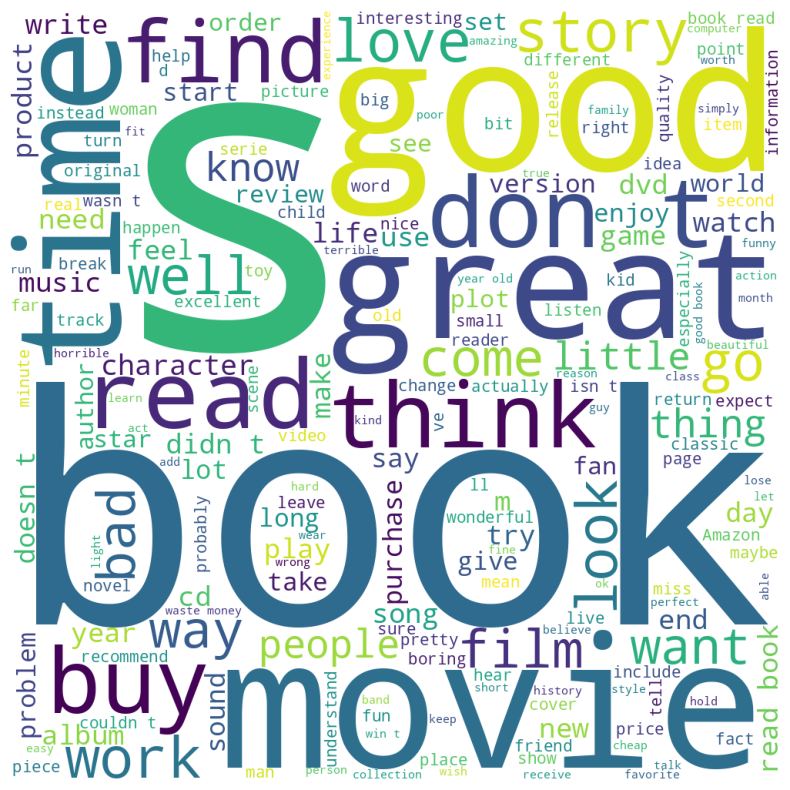

In [21]:
def word_cloud(image):
  plt.figure(figsize=(10,10))
  plt.imshow(image)
  plt.axis('off')
word_cloud(word_c)

Sentiment Distribution:
---

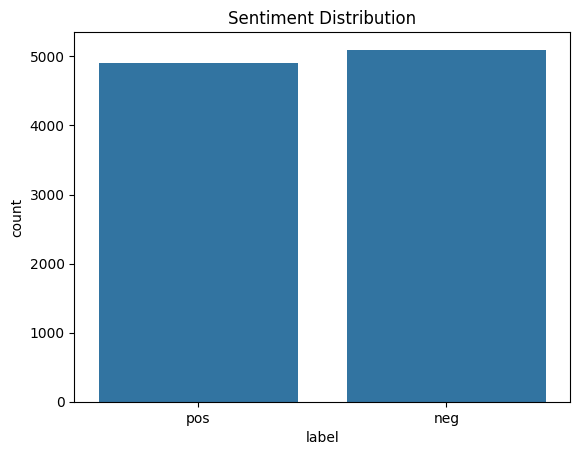

In [22]:
sns.countplot(data=df, x='label')
plt.title('Sentiment Distribution')
plt.show()

Positive/negative words:
---

In [23]:
df['len'] = df['review'].apply(len)

array([<Axes: title={'center': 'neg'}>, <Axes: title={'center': 'pos'}>],
      dtype=object)

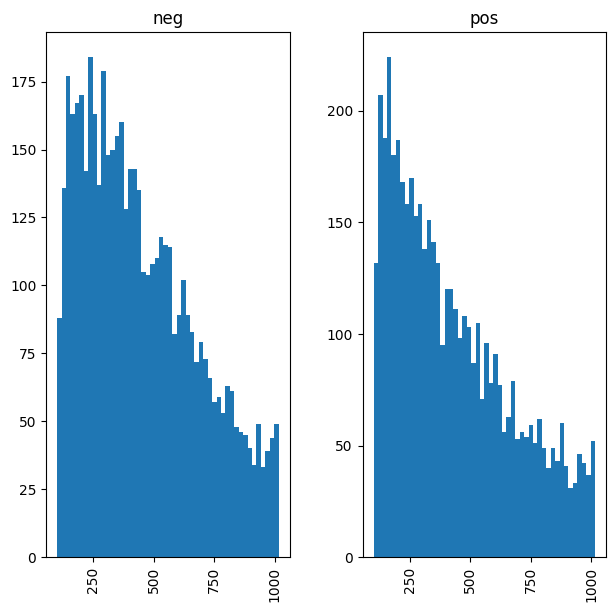

In [24]:
df.hist('len', by='label', bins=50, figsize=(7, 7))

Explanation:
---

In this step, I explored the dataset to understand text patterns and sentiment distribution.

1. Word Cloud:
I generated a word cloud using cleaned reviews after removing stopwords.
This shows the most frequent words in larger size, helping to see what users commonly talk about.

2. Sentiment Distribution:
I used a count plot on the label column to check how many positive and negative reviews are present.
This helped verify that the dataset is balanced.

3. Review Length Analysis:
I created a len column to store the length of each review and plotted histograms by label.
This shows whether positive or negative reviews are generally longer or shorter.

Overall, this step helped me understand word frequency, sentiment balance, and review length patterns before model building.

# **`Model Development: `**

**Use NLP techniques (TF-IDF, Word2Vec, or BERT embeddings) with models like Logistic Regression, SVM, or Neural Networks.**


TF-IDF with Logistic Regression Model
---

In [25]:
x_train, x_test, y_train, y_test = train_test_split(df.review, df.label, train_size=0.8, random_state=200)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(8000,) (2000,) (8000,) (2000,)


In [26]:
from sklearn.pipeline import Pipeline

In [27]:
pipe_line = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range = (1,1), analyzer=data_clean)),
     ('log', LogisticRegression())
])

In [28]:
pipe_line.fit(x_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(analyzer=<function data_clean at 0x78e8943fa0c0>)),
                ('log', LogisticRegression())])

In [29]:
#prediction
y_pred = pipe_line.predict(x_test)

In [30]:
y_pred

array(['neg', 'neg', 'neg', ..., 'pos', 'pos', 'pos'], dtype=object)

Embedding with Neural Networks(RNN)
---

In [31]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization, Embedding

In [45]:
df['label'] = df['label'].map({'pos': 1, 'neg': 0})

In [54]:
df['label'].unique()

array([1, 0])

In [46]:
train_text, val_text, train_lab, val_lab = train_test_split(df['review'].to_numpy(), df['label'].to_numpy(), test_size = 0.2, random_state=50 )

In [47]:
train_text.shape, val_text.shape, train_lab.shape, val_lab.shape

((8000,), (2000,), (8000,), (2000,))

In [48]:
vect = TextVectorization(max_tokens=10000,
                         standardize='lower_and_strip_punctuation',
                         split='whitespace',
                         ngrams=None,
                         output_mode='int',
                         output_sequence_length=20)

In [49]:
vect.adapt(train_text)

In [50]:
#embedding

emb= Embedding(input_dim=10000,
               output_dim=128,
               embeddings_initializer='uniform',
               input_length=20)

In [51]:
#rnn

rnn = tf.keras.models.Sequential()
rnn.add(tf.keras.Input(shape=(1,), dtype=tf.string))
rnn.add(vect)
rnn.add(emb)
rnn.add(tf.keras.layers.SimpleRNN(units=64, return_sequences=True))
rnn.add(tf.keras.layers.SimpleRNN(units=32))
rnn.add(tf.keras.layers.Dense(1, activation='sigmoid'))

rnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_1            │ (None, 20)             │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 20, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 20, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_3 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,295,489 (4.94 MB)

 Trainable params: 1,295,489 (4.94 MB)

 Non-trainable params: 0 (0.00 B)

In [52]:
rnn.compile(optimizer = tf.keras.optimizers.Adam(),
            loss = tf.keras.losses.BinaryCrossentropy(),
            metrics = ['accuracy'])

In [53]:
history = rnn.fit(train_text, train_lab, epochs=10, validation_data=(val_text, val_lab), batch_size=10)

Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - accuracy: 0.6916 - loss: 0.5728 - val_accuracy: 0.8000 - val_loss: 0.4470
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.9078 - loss: 0.2345 - val_accuracy: 0.7835 - val_loss: 0.5043
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9678 - loss: 0.0862 - val_accuracy: 0.7935 - val_loss: 0.7302
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.9856 - loss: 0.0399 - val_accuracy: 0.7245 - val_loss: 0.8576
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9864 - loss: 0.0376 - val_accuracy: 0.7690 - val_loss: 0.8630
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.9948 - loss: 0.0180 - val_accuracy: 0.7825 - val_loss: 0.8392
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9921 - loss: 0.0244 - val_accuracy: 0.6900 - val_loss: 1.0947
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.9915 - loss: 0.0256 - 

In [55]:
val_loss, val_accuracy = rnn.evaluate(val_text, val_lab)
print(f'Validation Loss: {val_loss}, Validation Accuracy: {val_accuracy}')

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7781 - loss: 1.0262
Validation Loss: 1.0479658842086792, Validation Accuracy: 0.7789999842643738


In [56]:
pred = tf.squeeze(np.round(rnn.predict(val_text)))

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


In [57]:
accuracy_score(val_lab, pred)

0.779

Explanation:
---

In this step, I built a text classification model using TF-IDF Vectorization and Logistic Regression.
First, I split the dataset into training and testing.

Then I used Pipeline, which combines two steps:

1.	TF-IDF Vectorizer – converts review text into numerical feature vectors.
2.	Logistic Regression – trains a classifier on those vectors to predict whether the review is positive or negative.

The pipeline was fitted on the training data and predictions were generated on the test data.
This approach ensures clean preprocessing and efficient model building in a single flow.





And also built a text classification model using Text Embedding and Recurrent Neural Network (RNN). First, I split the dataset into training and testing.

Then I used layers, which combines steps:

1.	TextVectorization – converts review text into numerical word indices.
2.	Embedding Layer – transforms each word index into dense vector representations.
3.	Simple RNN – learns sequence patterns and context from the text.
4.	Dense Layer – predicts whether the review is positive or negative.

The model was fitted on the training data and predictions were generated on the validation data.

# **`Validation:`**

**Use train/test split, cross-validation, and metrics like accuracy, F1-score.**


In [58]:
#cross validation
score = cross_val_score(pipe_line, x_train, y_train, cv=5)

In [59]:
print("Cross Validation Scores:", score)
print("Average CV Score:", score.mean())

Cross Validation Scores: [0.848125 0.834375 0.844375 0.8325   0.8475  ]
Average CV Score: 0.841375


In [60]:
#accuracy score
accuracy_score(y_test, y_pred)

0.8465

In [61]:
#f1 score for postivie label
f1_score(y_test, y_pred, pos_label='pos')


0.8400208441896821

In [62]:
#f1 score for negative label
f1_score(y_test, y_pred, pos_label='neg')

0.8524747717443537

In [63]:
#classification report for better understanding
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         neg       0.86      0.84      0.85      1050
         pos       0.83      0.85      0.84       950

    accuracy                           0.85      2000
   macro avg       0.85      0.85      0.85      2000
weighted avg       0.85      0.85      0.85      2000



Explanation:
---

In this step, I evaluated the model performance using multiple validation techniques.

•	Train–Test Split: During model development, I split the dataset into 80% training and 20% testing data so the model learns on one portion and is evaluated on unseen data.

•	Cross-Validation: I applied 5-fold cross validation using cross_val_score to check the stability and consistency of the model across different data splits.

•	Accuracy Score: Measured the overall percentage of correct predictions made by the model.

•	F1-Score: Calculated F1 score separately for positive and negative labels to balance precision and recall, which is important in sentiment analysis.

•	Classification Report: Generated a classification report to view precision, recall, F1-score, and support for each class, giving a detailed performance summary instead of only one metric.

Overall, these validation methods show that the Logistic Regression model performs well and generalizes effectively on unseen review data.